In [1]:
# Gerekli kütüphaneler

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Grafiklerin notebook içerisinde görünmesini sağlar
%matplotlib inline

# Grafiklerde yazıların daha okunabilir olması için
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

In [2]:
# CSV dosyasını oku

df = pd.read_csv("gdp-vs-happiness.csv")

# Sütun adlarının başındaki ve sonundaki boşlukları temizle
df.columns = df.columns.str.strip()

# İlk 5 satırı göster
display(df.head())

,Entity,Code,Year,Life satisfaction,GDP per capita,World region according to OWID
0,Afghanistan,AFG,2000,NaN,1617.8264,Asia
1,Afghanistan,AFG,2001,NaN,1454.1108,Asia
2,Afghanistan,AFG,2002,NaN,1774.3087,Asia
3,Afghanistan,AFG,2003,NaN,1815.9282,Asia
4,Afghanistan,AFG,2004,NaN,1776.9182,Asia


In [3]:
print("Satır sayısı:", df.shape[0])
print("Sütun sayısı:", df.shape[1])

print("\nSütun adları:")
print(df.columns.tolist())

Satır sayısı: 7594
Sütun sayısı: 6

Sütun adları:
['Entity', 'Code', 'Year', 'Life satisfaction', 'GDP per capita', 'World region according to OWID']


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7594 entries, 0 to 7593
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Entity                          7594 non-null   object 
 1   Code                            7594 non-null   object 
 2   Year                            7594 non-null   int64  
 3   Life satisfaction               2270 non-null   float64
 4   GDP per capita                  7445 non-null   float64
 5   World region according to OWID  7029 non-null   object 
dtypes: float64(2), int64(1), object(3)
memory usage: 356.1+ KB


In [6]:
display(df.describe())

,Year,Life satisfaction,GDP per capita
count,7594.000000,2270.000000,7445.000000
mean,2007.888728,5.475788,22020.575246
std,10.349477,1.117284,24019.749943
min,1990.000000,1.364000,510.822800
25%,1999.000000,4.605500,4597.220000
50%,2008.000000,5.477000,12807.166000
75%,2017.000000,6.343750,32722.330000
max,2025.000000,7.856000,174569.520000


In [7]:
print("Farklı ülke/bölge sayısı:", df["Entity"].nunique())

print("Başlangıç yılı:", df["Year"].min())

print("Bitiş yılı:", df["Year"].max())

print("Farklı yıl sayısı:", df["Year"].nunique())

Farklı ülke/bölge sayısı: 225
Başlangıç yılı: 1990
Bitiş yılı: 2025
Farklı yıl sayısı: 36


In [8]:
print(sorted(df["Entity"].dropna().unique()))

['Afghanistan', 'Africa', 'Albania', 'Algeria', 'Andorra', 'Angola', 'Antigua and Barbuda', 'Argentina', 'Armenia', 'Aruba', 'Asia', 'Australia', 'Austria', 'Azerbaijan', 'Bahamas', 'Bahrain', 'Bangladesh', 'Barbados', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bermuda', 'Bhutan', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Brunei', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Canada', 'Cape Verde', 'Cayman Islands', 'Central African Republic', 'Chad', 'Chile', 'China', 'Colombia', 'Comoros', 'Congo', 'Costa Rica', "Cote d'Ivoire", 'Croatia', 'Cuba', 'Curacao', 'Cyprus', 'Czechia', 'Democratic Republic of Congo', 'Denmark', 'Djibouti', 'Dominica', 'Dominican Republic', 'East Asia and Pacific (WB)', 'East Timor', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Estonia', 'Eswatini', 'Ethiopia', 'Europe', 'Europe and Central Asia (WB)', 'European Union (27)', 'Faroe Islands', 'Fiji', 'Finland', 'France', 'Gabon', 'Gambia', 'Georgia', 'Germany', '

In [9]:
eksik_sayilari = df.isnull().sum()

print(eksik_sayilari)

Entity                               0
Code                                 0
Year                                 0
Life satisfaction                 5324
GDP per capita                     149
World region according to OWID     565
dtype: int64


In [11]:
eksik_oranlari=(df.isnull().mean()*100).round(2)

print(eksik_oranlari)                                        

Entity                             0.00
Code                               0.00
Year                               0.00
Life satisfaction                 70.11
GDP per capita                     1.96
World region according to OWID     7.44
dtype: float64


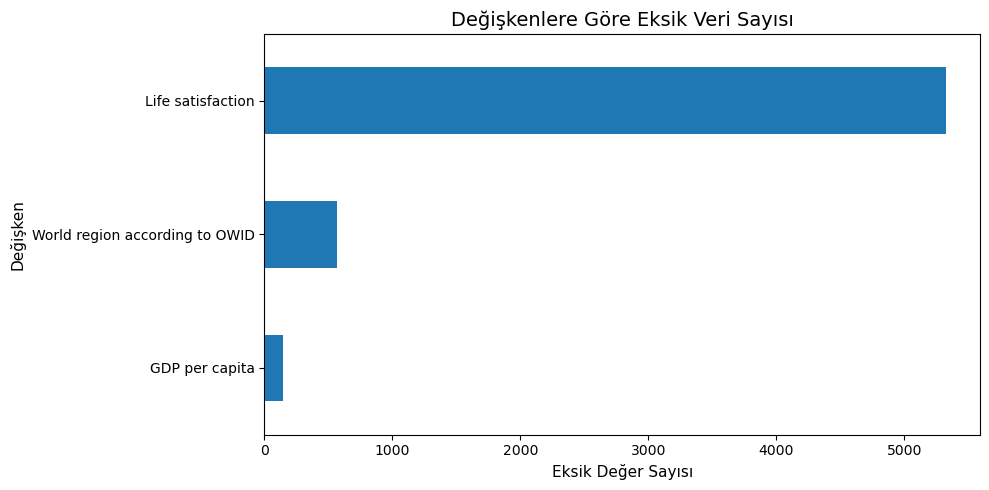

In [12]:
eksik_sayilari = df.isnull().sum()

eksik_sayilari = eksik_sayilari[eksik_sayilari > 0]

plt.figure(figsize=(10, 5))

eksik_sayilari.sort_values().plot(
    kind="barh"
)

plt.title("Değişkenlere Göre Eksik Veri Sayısı")
plt.xlabel("Eksik Değer Sayısı")
plt.ylabel("Değişken")

plt.tight_layout()
plt.show()

In [13]:
df_clean=df.copy()

In [14]:
# Metin sütunlarını düzenle

df_clean["Entity"] = df_clean["Entity"].astype("string").str.strip()

df_clean["Code"] = df_clean["Code"].astype("string").str.strip()

df_clean["World region according to OWID"] = (
    df_clean["World region according to OWID"]
    .astype("string")
    .str.strip()
)

# Sayısal sütunları dönüştür

df_clean["Year"] = pd.to_numeric(
    df_clean["Year"],
    errors="coerce"
)

df_clean["Life satisfaction"] = pd.to_numeric(
    df_clean["Life satisfaction"],
    errors="coerce"
)

df_clean["GDP per capita"] = pd.to_numeric(
    df_clean["GDP per capita"],
    errors="coerce"
)

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7594 entries, 0 to 7593
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Entity                          7594 non-null   string 
 1   Code                            7594 non-null   string 
 2   Year                            7594 non-null   int64  
 3   Life satisfaction               2270 non-null   float64
 4   GDP per capita                  7445 non-null   float64
 5   World region according to OWID  7029 non-null   string 
dtypes: float64(2), int64(1), string(3)
memory usage: 356.1 KB


In [20]:
print(
    "Tamamen yinelenen satır:",
    df_clean.duplicated().sum()
)

Tamamen yinelenen satır: 0


In [21]:
print(
    "Aynı ülke ve yıla ait yinelenen kayıt:",
    df_clean.duplicated(
        subset=["Entity", "Year"]
    ).sum()
)

Aynı ülke ve yıla ait yinelenen kayıt: 0


In [22]:
print(
    "Ülke adı eksik:",
    df_clean["Entity"].isnull().sum()
)

print(
    "Ülke kodu eksik:",
    df_clean["Code"].isnull().sum()
)

print(
    "Yıl eksik:",
    df_clean["Year"].isnull().sum()
)

Ülke adı eksik: 0
Ülke kodu eksik: 0
Yıl eksik: 0


In [23]:
df_clean = df_clean.dropna(
    subset=["Entity", "Code", "Year"]
).copy()

df_clean["Year"] = df_clean["Year"].astype(int)

print("Ön işleme sonrası boyut:", df_clean.shape)

Ön işleme sonrası boyut: (7594, 6)


In [24]:
gecersiz_memnuniyet = df_clean[
    df_clean["Life satisfaction"].notna()
    &
    ~df_clean["Life satisfaction"].between(0, 10)
]

print("Geçersiz yaşam memnuniyeti değeri:")
display(gecersiz_memnuniyet)

Geçersiz yaşam memnuniyeti değeri:


,Entity,Code,Year,Life satisfaction,GDP per capita,World region according to OWID


In [25]:
gecersiz_gsyh = df_clean[
    df_clean["GDP per capita"].notna()
    &
    (df_clean["GDP per capita"] <= 0)
]

print("Sıfır veya negatif GSYH değeri:")
display(gecersiz_gsyh)

Sıfır veya negatif GSYH değeri:


,Entity,Code,Year,Life satisfaction,GDP per capita,World region according to OWID


In [26]:
# Yalnızca doğrulama sonucunda geçersiz olduğu belirlenen
# değerler varsa bunları eksik değer olarak işaretle.

df_clean.loc[
    df_clean["Life satisfaction"].notna()
    & ~df_clean["Life satisfaction"].between(0, 10),
    "Life satisfaction"
] = np.nan

df_clean.loc[
    df_clean["GDP per capita"].notna()
    & (df_clean["GDP per capita"] <= 0),
    "GDP per capita"
] = np.nan

In [27]:
# Yalnızca doğrulama sonucunda geçersiz olduğu belirlenen
# değerler varsa bunları eksik değer olarak işaretle.

df_clean.loc[
    df_clean["Life satisfaction"].notna()
    & ~df_clean["Life satisfaction"].between(0, 10),
    "Life satisfaction"
] = np.nan

df_clean.loc[
    df_clean["GDP per capita"].notna()
    & (df_clean["GDP per capita"] <= 0),
    "GDP per capita"
] = np.nan

In [28]:
gsyh = df_clean["GDP per capita"].dropna()

Q1 = gsyh.quantile(0.25)
Q3 = gsyh.quantile(0.75)

IQR = Q3 - Q1

alt_sinir = Q1 - 1.5 * IQR
ust_sinir = Q3 + 1.5 * IQR

aykiri_gsyh = df_clean[
    df_clean["GDP per capita"].notna()
    &
    (
        (df_clean["GDP per capita"] < alt_sinir)
        |
        (df_clean["GDP per capita"] > ust_sinir)
    )
]

print("Alt sınır:", alt_sinir)
print("Üst sınır:", ust_sinir)

print("Aykırı olarak işaretlenen kayıt sayısı:", len(aykiri_gsyh))

display(aykiri_gsyh.head(10))

Alt sınır: -37590.445
Üst sınır: 74909.995
Aykırı olarak işaretlenen kayıt sayısı: 283


,Entity,Code,Year,Life satisfaction,GDP per capita,World region according to OWID
736,Bermuda,BMU,1990,NaN,79750.860,North America
737,Bermuda,BMU,1991,NaN,76368.270,North America
738,Bermuda,BMU,1992,NaN,75769.910,North America
739,Bermuda,BMU,1993,NaN,77506.740,North America
740,Bermuda,BMU,1994,NaN,77473.580,North America
741,Bermuda,BMU,1995,NaN,80430.640,North America
742,Bermuda,BMU,1996,NaN,82126.260,North America
743,Bermuda,BMU,1997,NaN,85384.445,North America
744,Bermuda,BMU,1998,NaN,88038.540,North America
745,Bermuda,BMU,1999,NaN,90294.380,North America


In [29]:
avrupa_turkiye = df_clean[
    (
        df_clean["World region according to OWID"] == "Europe"
    )
    |
    (
        df_clean["Entity"] == "Turkey"
    )
].copy()

print("Seçilen veri boyutu:", avrupa_turkiye.shape)

print(
    "Seçilen ülke/bölge sayısı:",
    avrupa_turkiye["Entity"].nunique()
)

print(
    sorted(avrupa_turkiye["Entity"].unique())
)

Seçilen veri boyutu: (1562, 6)
Seçilen ülke/bölge sayısı: 45
['Albania', 'Andorra', 'Austria', 'Belarus', 'Belgium', 'Bosnia and Herzegovina', 'Bulgaria', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Estonia', 'Faroe Islands', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Iceland', 'Ireland', 'Italy', 'Kosovo', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'Moldova', 'Montenegro', 'Netherlands', 'North Macedonia', 'Norway', 'Poland', 'Portugal', 'Romania', 'Russia', 'San Marino', 'Serbia', 'Slovakia', 'Slovenia', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'Ukraine', 'United Kingdom']


In [30]:
turkiye = avrupa_turkiye[
    avrupa_turkiye["Entity"] == "Turkey"
].sort_values("Year")

display(turkiye)

,Entity,Code,Year,Life satisfaction,GDP per capita,World region according to OWID
6952,Turkey,TUR,1990,NaN,12184.199,Asia
6953,Turkey,TUR,1991,NaN,12057.936,Asia
6954,Turkey,TUR,1992,NaN,12451.045,Asia
6955,Turkey,TUR,1993,NaN,13174.467,Asia
6956,Turkey,TUR,1994,NaN,12343.004,Asia
6957,Turkey,TUR,1995,NaN,13099.258,Asia
6958,Turkey,TUR,1996,NaN,13826.920,Asia
6959,Turkey,TUR,1997,NaN,14631.296,Asia
6960,Turkey,TUR,1998,NaN,14704.339,Asia
6961,Turkey,TUR,1999,NaN,14066.189,Asia


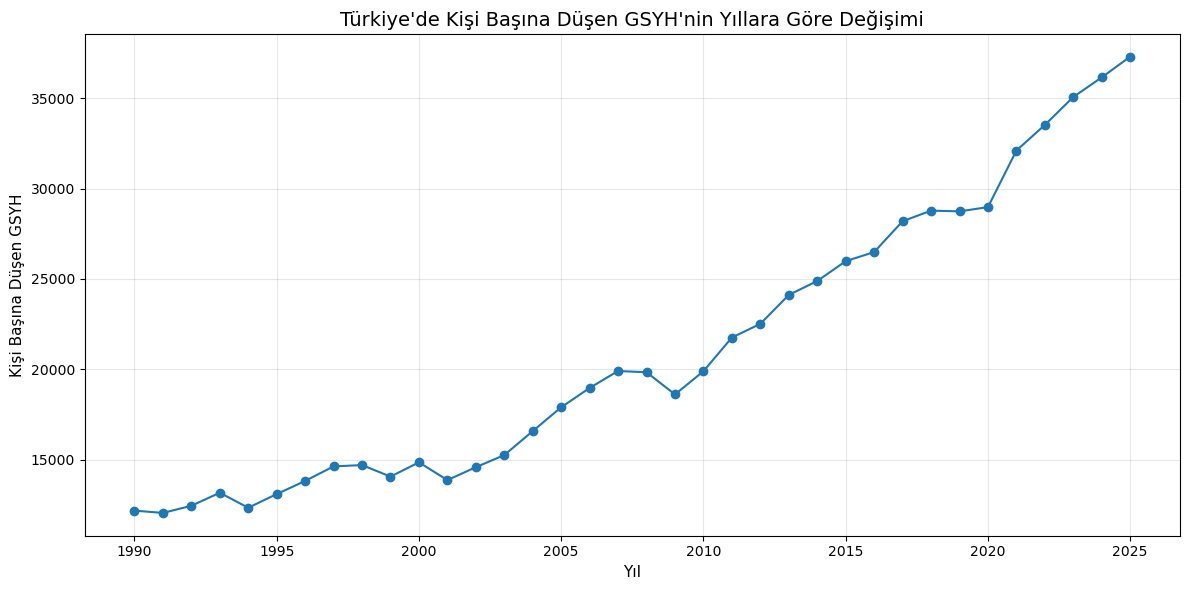

In [31]:
turkiye_gsyh = turkiye.dropna(
    subset=["GDP per capita"]
).sort_values("Year")

plt.figure(figsize=(12, 6))

plt.plot(
    turkiye_gsyh["Year"],
    turkiye_gsyh["GDP per capita"],
    marker="o"
)

plt.title("Türkiye'de Kişi Başına Düşen GSYH'nin Yıllara Göre Değişimi")
plt.xlabel("Yıl")
plt.ylabel("Kişi Başına Düşen GSYH")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

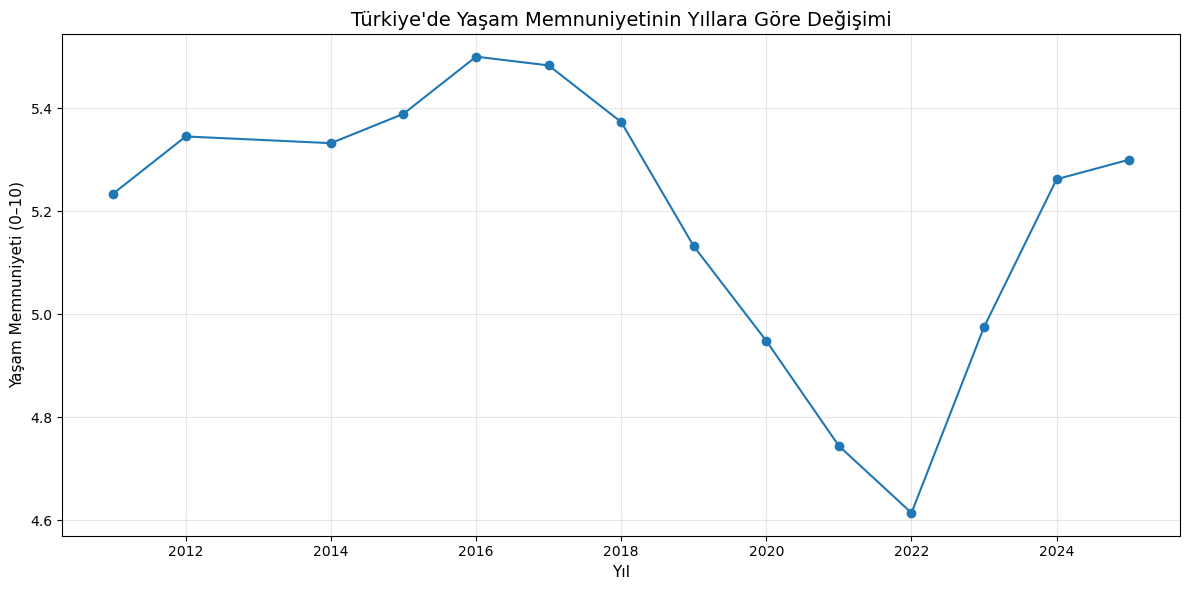

In [32]:
turkiye_memnuniyet = turkiye.dropna(
    subset=["Life satisfaction"]
).sort_values("Year")

plt.figure(figsize=(12, 6))

plt.plot(
    turkiye_memnuniyet["Year"],
    turkiye_memnuniyet["Life satisfaction"],
    marker="o"
)

plt.title("Türkiye'de Yaşam Memnuniyetinin Yıllara Göre Değişimi")
plt.xlabel("Yıl")
plt.ylabel("Yaşam Memnuniyeti (0–10)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
korelasyon_verisi = avrupa_turkiye[
    [
        "GDP per capita",
        "Life satisfaction"
    ]
].dropna()

korelasyon = korelasyon_verisi.corr()

display(korelasyon)

,GDP per capita,Life satisfaction
GDP per capita,1.000000,0.743637
Life satisfaction,0.743637,1.000000


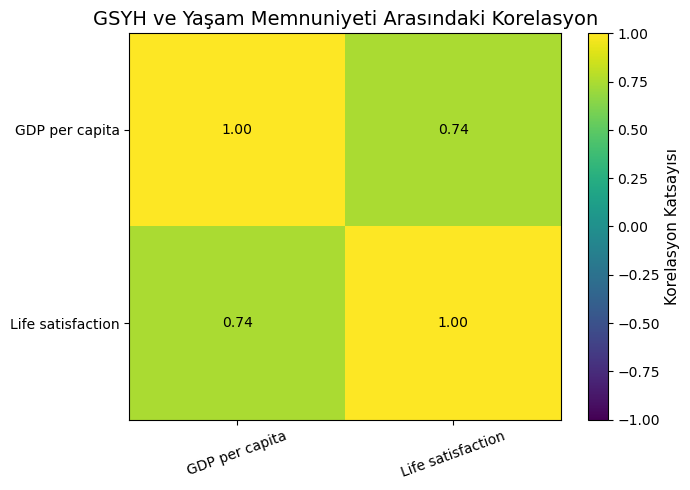

In [34]:
plt.figure(figsize=(7, 5))

plt.imshow(
    korelasyon,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

plt.colorbar(label="Korelasyon Katsayısı")

plt.xticks(
    range(len(korelasyon.columns)),
    korelasyon.columns,
    rotation=20
)

plt.yticks(
    range(len(korelasyon.index)),
    korelasyon.index
)

for i in range(len(korelasyon.index)):
    for j in range(len(korelasyon.columns)):
        plt.text(
            j,
            i,
            f"{korelasyon.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("GSYH ve Yaşam Memnuniyeti Arasındaki Korelasyon")

plt.tight_layout()
plt.show()

Grafikte kullanılan yıl: 2025
Gözlem sayısı: 41


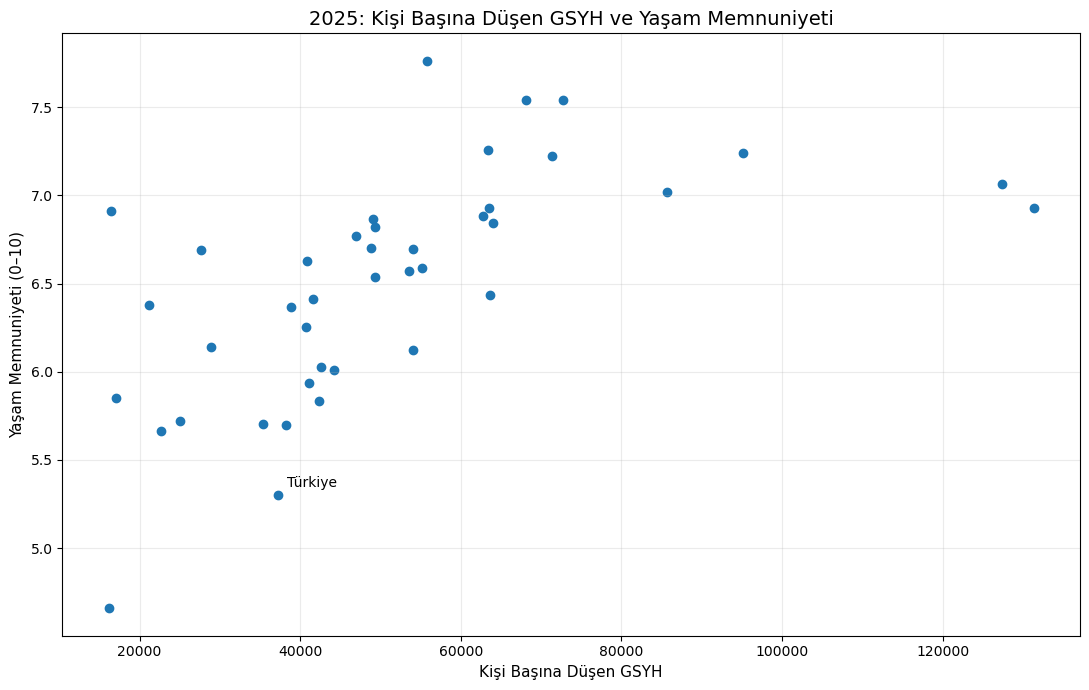

In [35]:
eslesmis = avrupa_turkiye.dropna(
    subset=["GDP per capita", "Life satisfaction"]
).copy()

# En az 10 gözlem bulunan yıllar
yil_sayilari = eslesmis.groupby("Year").size()

uygun_yillar = yil_sayilari[yil_sayilari >= 10]

if uygun_yillar.empty:
    raise ValueError("Karşılaştırma için yeterli ortak verisi bulunan yıl bulunamadı.")

# Yeterli verisi bulunan en son yıl
son_yil = int(uygun_yillar.index.max())

grafik_verisi = eslesmis[
    eslesmis["Year"] == son_yil
].copy()

print("Grafikte kullanılan yıl:", son_yil)
print("Gözlem sayısı:", len(grafik_verisi))

plt.figure(figsize=(11, 7))

plt.scatter(
    grafik_verisi["GDP per capita"],
    grafik_verisi["Life satisfaction"]
)

# Türkiye'nin konumunu belirt
turkiye_noktasi = grafik_verisi[
    grafik_verisi["Entity"] == "Turkey"
]

for _, satir in turkiye_noktasi.iterrows():
    plt.annotate(
        "Türkiye",
        (
            satir["GDP per capita"],
            satir["Life satisfaction"]
        ),
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.title(
    f"{son_yil}: Kişi Başına Düşen GSYH ve Yaşam Memnuniyeti"
)

plt.xlabel("Kişi Başına Düşen GSYH")
plt.ylabel("Yaşam Memnuniyeti (0–10)")

plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

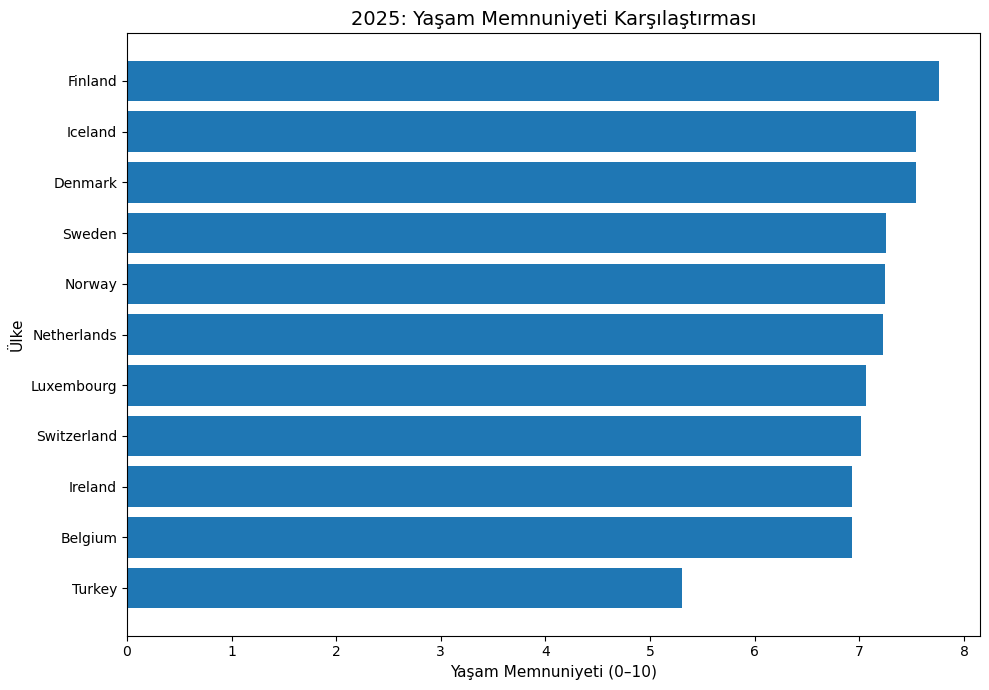

In [36]:
yasam_yillari = avrupa_turkiye.dropna(
    subset=["Life satisfaction"]
)

son_memnuniyet_yili = int(
    yasam_yillari["Year"].max()
)

siralama = yasam_yillari[
    yasam_yillari["Year"] == son_memnuniyet_yili
].copy()

siralama = siralama.sort_values(
    "Life satisfaction",
    ascending=False
)

# İlk 10 ülke
ilk_10 = siralama.head(10).copy()

# Türkiye ilk 10'da değilse ayrıca ekle
turkiye_satiri = siralama[
    siralama["Entity"] == "Turkey"
]

grafik_siralama = pd.concat(
    [ilk_10, turkiye_satiri]
).drop_duplicates(
    subset=["Entity"]
)

grafik_siralama = grafik_siralama.sort_values(
    "Life satisfaction",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    grafik_siralama["Entity"],
    grafik_siralama["Life satisfaction"]
)

plt.title(
    f"{son_memnuniyet_yili}: Yaşam Memnuniyeti Karşılaştırması"
)

plt.xlabel("Yaşam Memnuniyeti (0–10)")
plt.ylabel("Ülke")

plt.tight_layout()
plt.show()

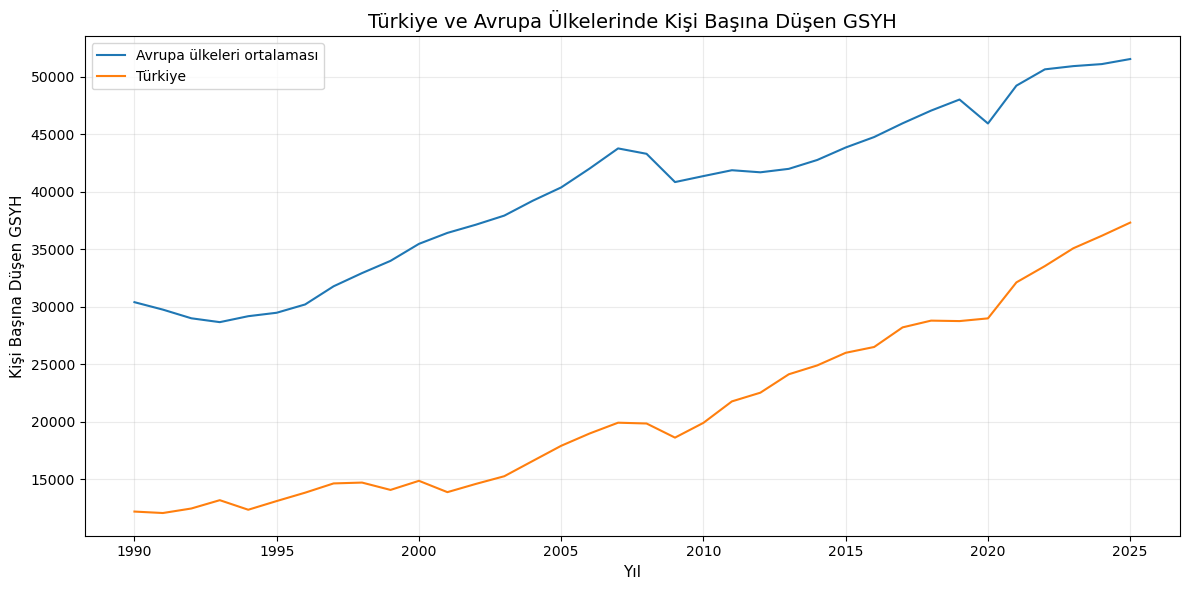

In [37]:
avrupa_turkiye["Grup"] = np.where(
    avrupa_turkiye["Entity"] == "Turkey",
    "Türkiye",
    "Avrupa ülkeleri ortalaması"
)

gsyh_trendi = (
    avrupa_turkiye
    .dropna(subset=["GDP per capita"])
    .groupby(["Year", "Grup"])["GDP per capita"]
    .mean()
    .unstack()
    .reindex(range(1990, 2026))
)

plt.figure(figsize=(12, 6))

for grup in gsyh_trendi.columns:
    plt.plot(
        gsyh_trendi.index,
        gsyh_trendi[grup],
        label=grup
    )

plt.title("Türkiye ve Avrupa Ülkelerinde Kişi Başına Düşen GSYH")
plt.xlabel("Yıl")
plt.ylabel("Kişi Başına Düşen GSYH")

plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

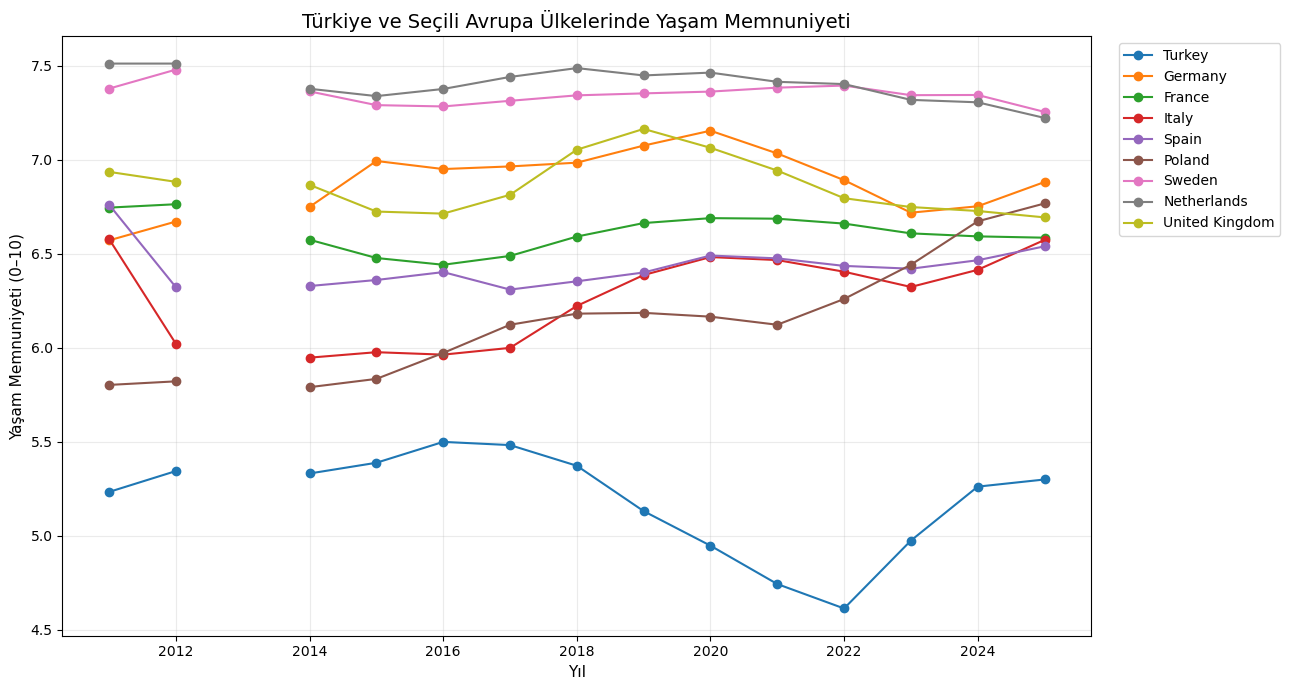

In [38]:
secili_ulkeler = [
    "Turkey",
    "Germany",
    "France",
    "Italy",
    "Spain",
    "Poland",
    "Sweden",
    "Netherlands",
    "United Kingdom"
]

memnuniyet_trendi = avrupa_turkiye[
    avrupa_turkiye["Entity"].isin(secili_ulkeler)
].pivot(
    index="Year",
    columns="Entity",
    values="Life satisfaction"
).reindex(
    index=range(2011, 2026)
)

plt.figure(figsize=(13, 7))

for ulke in secili_ulkeler:
    if ulke in memnuniyet_trendi.columns:
        plt.plot(
            memnuniyet_trendi.index,
            memnuniyet_trendi[ulke],
            marker="o",
            label=ulke
        )

plt.title("Türkiye ve Seçili Avrupa Ülkelerinde Yaşam Memnuniyeti")
plt.xlabel("Yıl")
plt.ylabel("Yaşam Memnuniyeti (0–10)")

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

In [39]:
son_yil_verisi = avrupa_turkiye[
    avrupa_turkiye["Year"] == son_memnuniyet_yili
]

turkiye_degeri = son_yil_verisi.loc[
    son_yil_verisi["Entity"] == "Turkey",
    "Life satisfaction"
].mean()

avrupa_ortalamasi = son_yil_verisi.loc[
    son_yil_verisi["World region according to OWID"] == "Europe",
    "Life satisfaction"
].mean()

print("Karşılaştırma yılı:", son_memnuniyet_yili)
print("Türkiye yaşam memnuniyeti:", turkiye_degeri)
print("Avrupa ülkeleri basit ortalaması:", avrupa_ortalamasi)

Karşılaştırma yılı: 2025
Türkiye yaşam memnuniyeti: 5.3
Avrupa ülkeleri basit ortalaması: 6.530525


In [40]:
gsyh_son_yil = avrupa_turkiye[
    avrupa_turkiye["Year"] == son_yil
]

turkiye_gsyh_degeri = gsyh_son_yil.loc[
    gsyh_son_yil["Entity"] == "Turkey",
    "GDP per capita"
].mean()

avrupa_gsyh_ortalamasi = gsyh_son_yil.loc[
    gsyh_son_yil["World region according to OWID"] == "Europe",
    "GDP per capita"
].mean()

print("GSYH karşılaştırma yılı:", son_yil)
print("Türkiye GSYH değeri:", turkiye_gsyh_degeri)
print("Avrupa ülkeleri basit ortalaması:", avrupa_gsyh_ortalamasi)

GSYH karşılaştırma yılı: 2025
Türkiye GSYH değeri: 37300.75
Avrupa ülkeleri basit ortalaması: 51518.348523809516


In [48]:
from pathlib import Path

Path("data/processed").mkdir(
    parents=True,
    exist_ok=True
)

Path("figures").mkdir(
    parents=True,
    exist_ok=True
)

In [49]:
df_clean.to_csv(
    "data/processed/gdp_happiness_clean.csv",
    index=False
)

In [50]:
avrupa_turkiye.to_csv(
    "data/processed/turkey_europe_data.csv",
    index=False
)

In [51]:
site_verisi = avrupa_turkiye[
    [
        "Entity",
        "Code",
        "Year",
        "Life satisfaction",
        "GDP per capita",
        "World region according to OWID"
    ]
].rename(
    columns={
        "Entity": "country",
        "Code": "code",
        "Year": "year",
        "Life satisfaction": "life_satisfaction",
        "GDP per capita": "gdp_per_capita",
        "World region according to OWID": "region"
    }
)

site_verisi.to_json(
    "data/processed/turkey_europe_data.json",
    orient="records",
    force_ascii=False,
    indent=2
)

In [52]:
plt.savefig(
    "figures/grafik_adi.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 1000x600 with 0 Axes>

In [47]:
plt.savefig(
    "figures/turkiye_gsyh.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 1000x600 with 0 Axes>

In [53]:
import os
print(os.getcwd())                     # çalışma klasörü
print(os.path.abspath("ozet.json"))    # dosya adını kendi dosyanla değiştir
print(os.path.exists("ozet.json"))  e   # True ise burada
print(os.listdir())                    # klasördeki dosyaları listeler

C:\Users\Casper
C:\Users\Casper\ozet.json
False
['-1.14-windows.xml', '.anaconda', '.android', '.cache', '.codex', '.conda', '.continuum', '.copilot', '.ipynb_checkpoints', '.ipython', '.jupyter', '.matplotlib', '.python_history', '.templateengine', '.vscode', '.vscode-shared', '22 NİSAN.mdf', '22 NİSAN_log.ldf', '605.mdf', '605_log.ldf', 'anaconda3', 'anaconda_projects', 'AppData', 'Application Data', 'Belgelerim', 'Contacts', 'Cookies', 'Crop_recommendationV2.csv', 'Crop_recommendation_on_islenmis.csv', 'data', 'db_MYO.mdf', 'db_MYO_log.ldf', 'db_Test2.mdf', 'db_Test2_log.ldf', 'Desktop', 'Documents', 'Downloads', 'Favorites', 'figures', 'FilmPlatformu.mdf', 'FilmPlatformu_log.ldf', 'final_temiz_veri.csv', 'final_temiz_veri_v1.xlsx', 'final_temiz_veri_v2.xlsx', 'gdp-vs-happiness.csv', 'kadin_cinayetleri_kusursuz_son_hali.xlsx', 'kadin_cinayetleri_lojistik_model.pkl', 'kadin_cinayetleri_lojistik_model.xlsx', 'kadin_cinayetleri_son_hali.xlsx', 'kadin_cinayetleri_tam_temiz.xlsx', 'kadin